# Preprocessing

Install local dependencies from the project root with `python -m pip install -r requirements.txt`.

Set `DATA_SOURCE` to `"local"` for a file available to the selected kernel, or `"drive"` for Google Drive on a Colab kernel. Update the matching path below, then run the cells in order. In VS Code, the selected kernel determines where code runs.


In [1]:
from pathlib import Path

import pandas as pd

DATA_SOURCE = "local"  # "local" or "drive"
LOCAL_DATA_PATH = Path("data/raw/H2.csv")
DRIVE_DATA_PATH = Path("/content/drive/MyDrive/hotel-booking-project/data/H2.csv")

PROJECT_ROOT = Path.cwd().parent

## Select the data source

Local paths are relative to the project root unless you provide an absolute path. Drive mode mounts Google Drive and uses `DRIVE_DATA_PATH`; it requires a Colab kernel. With a remote kernel, local mode reads files on the remote machine, not your Windows computer.


In [2]:
if DATA_SOURCE == "local":
    DATA_PATH = LOCAL_DATA_PATH.expanduser()
    if not DATA_PATH.is_absolute():
        DATA_PATH = PROJECT_ROOT / DATA_PATH
elif DATA_SOURCE == "drive":
    try:
        from google.colab import drive
    except ImportError as error:
        raise RuntimeError(
            "Drive mode requires a Colab kernel. Select Colab in VS Code, "
            "or use local mode with a downloaded or synced file."
        ) from error

    drive.mount("/content/drive")
    DATA_PATH = DRIVE_DATA_PATH.expanduser()


## Load the original data



In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Update LOCAL_DATA_PATH or DRIVE_DATA_PATH "
        "in the setup cell, then rerun the cells in order."
    )

df = pd.read_csv(DATA_PATH, dtype="string", keep_default_na=False)
df.shape

(79330, 31)

## Basic Preprocessing



first, we drop the Agent & Company id columns, as they may be NULL which can cause data leakage in the future. *meaning that data which is not gauranteed to be avalaible in prediction is used in training*

In [4]:
df = df.drop(columns=["Agent","Company"])
df.shape

(79330, 29)

The entire dataset is stored as strings, however there are a lot of numerical columns, therefore we need to convert these to numerical format so that we can do the correct operations on them. 
Before doing that, we need to replace all non numerical values in the numerical columns such as `NA` with suitable numerical values.

In [5]:
numerical_columns = [
    "IsCanceled",
    "LeadTime",
    "ArrivalDateYear",
    "ArrivalDateWeekNumber",
    "ArrivalDateDayOfMonth",
    "StaysInWeekendNights",
    "StaysInWeekNights",
    "Adults",
    "Children",
    "Babies",
    "IsRepeatedGuest",
    "PreviousCancellations",
    "PreviousBookingsNotCanceled",
    "BookingChanges",
    "DaysInWaitingList",
    "ADR",
    "RequiredCarParkingSpaces",
    "TotalOfSpecialRequests",
]

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values="NA",strategy="constant",fill_value="-1")

imputer = imputer.fit(df[numerical_columns])
df[numerical_columns] = imputer.transform(df[numerical_columns])

In [8]:
for column in numerical_columns:
    df[column] = pd.to_numeric(df[column])

In [11]:
df[numerical_columns].describe()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000
mean,0.417270,109.735724,2016.174285,27.177449,15.786625,0.795185,2.182957,1.850977,0.091315,0.004941,0.025615,0.079743,0.132371,0.187369,3.226774,105.304465,0.024367,0.546918
std,0.493111,110.948526,0.699181,13.398523,8.728451,0.885026,1.456416,0.509292,0.372248,0.084323,0.157983,0.415472,1.693411,0.608620,20.870890,43.602954,0.154919,0.780776
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,23.000000,2016.000000,17.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,79.200000,0.000000,0.000000
50%,0.000000,74.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,99.900000,0.000000,0.000000
75%,1.000000,163.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,629.000000,2017.000000,53.000000,31.000000,16.000000,41.000000,4.000000,3.000000,10.000000,1.000000,21.000000,72.000000,21.000000,391.000000,5400.000000,3.000000,5.000000


now that the columns are in numerical format, we can visualize all the numerical columns against each other in one big heatmap

<Axes: >

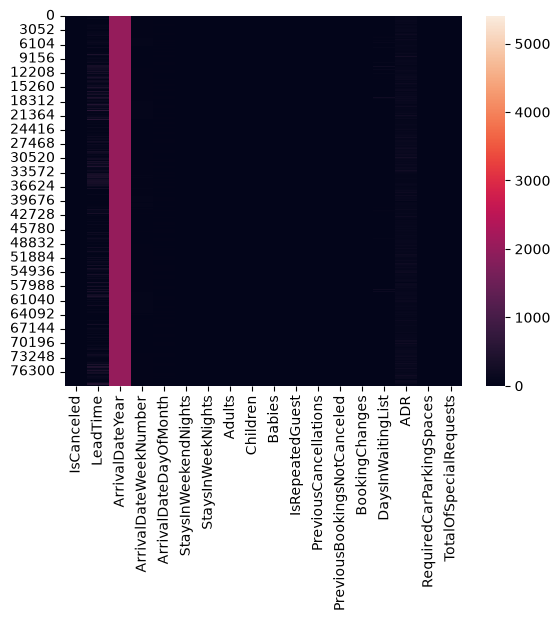

In [ ]:
import seaborn as sns
df_visual = df[numerical_columns].pivot(index="Model", columns="Task", values="Score")
sns.heatmap(df_visual)